# `vkplot` Demo — `hvPlot`-Style Vulkan GPU Plotting

Just like `import hvplot.pandas` adds `.hvplot` to pandas, **`import vkplot.vkpandas`** (or `import vkplot`) attaches the **`.vkplot`** accessor to `vkpandas.DataFrame`, `vkpandas.Series`, and `vkspatial.GeoDataFrame`.

Every plot runs on **Vulkan GPU** (`vknumpy` + `vkshader` + `vkholoviews`) and composes with `*`, `+`, `.opts()`, `.cols()`, and `.interact()`.

In [1]:
import sys, time
from pathlib import Path

_root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import vknumpy as vnp
import vkpandas as vpd
import vkspatial as vksp
import vkplot.vkpandas  # registers .vkplot on DataFrame, Series, and GeoDataFrame

taxi_path = Path.home() / ".cache/hvsampledata/nyc_taxi/v2/nyc_taxi_wide.parq"
t0 = time.perf_counter()
df = vpd.read_parquet(taxi_path, columns=["pickup_x", "pickup_y", "fare_amount", "tip_amount", "pickup_hour"])
df["pickup_hour"] = df["pickup_hour"].astype(vnp.int32)
clean = df[df["fare_amount"] > 0.0]
clean["tip_pct"] = (clean["tip_amount"] / clean["fare_amount"]) * 100.0
by_hour = clean[["pickup_hour", "fare_amount", "tip_pct"]].groupby("pickup_hour").mean()
print(f"Loaded {len(df):,} NYC Taxi trips on GPU in {time.perf_counter() - t0:.2f}s")

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


Loaded 11,842,094 NYC Taxi trips on GPU in 3.11s


## 1. One-Liner GPU Dashboard (`points`, `Series.vkplot.hist`, `bar`, `line`)

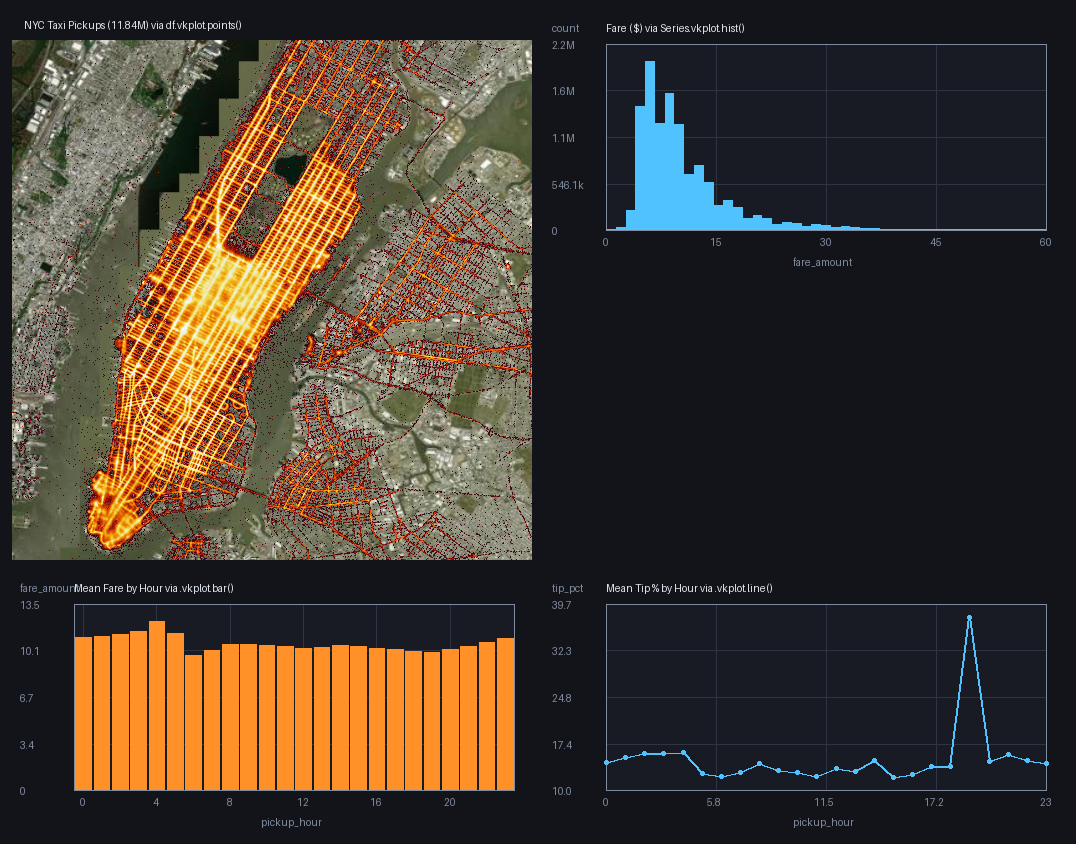

In [2]:
taxi_map = df.vkplot.points(
    "pickup_x", "pickup_y", tiles="esri", how="eq_hist",
    width=520, height=520, xlim=(-8242000, -8226000), ylim=(4968000, 4985000),
    title="NYC Taxi Pickups (11.84M) via df.vkplot.points()",
)
fare_hist = clean["fare_amount"].vkplot.hist(
    bins=45, range=(0, 60), width=520, height=260, title="Fare ($) via Series.vkplot.hist()"
)
hourly_bar = by_hour.vkplot.bar(
    "pickup_hour", "fare_amount", width=520, height=260, title="Mean Fare by Hour via .vkplot.bar()"
)
hourly_line = by_hour.vkplot.line(
    "pickup_hour", "tip_pct", width=520, height=260, title="Mean Tip % by Hour via .vkplot.line()"
)

(taxi_map + fare_hist + hourly_bar + hourly_line).cols(2)

## 2. Live Linked Cross-Filtering Map in 3 Lines (`.vkplot` + `.interact()`)

In [3]:
(
    df.vkplot.points("pickup_x", "pickup_y", tiles="esri", width=580, height=540, xlim=(-8242000, -8226000), ylim=(4968000, 4985000))
    + df.vkplot.hist("fare_amount", bins=40, range=(0, 60), width=400, height=260, title="Viewport Fare ($)")
    + df.vkplot.hist("tip_amount",  bins=40, range=(0, 15), width=400, height=260, title="Viewport Tip ($)")
).interact();

## 3. `vkspatial.GeoDataFrame.vkplot` (Automatic Spatial Columns + GPU Polygon Filter)

Midtown Manhattan pickups: 3,718,100


[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


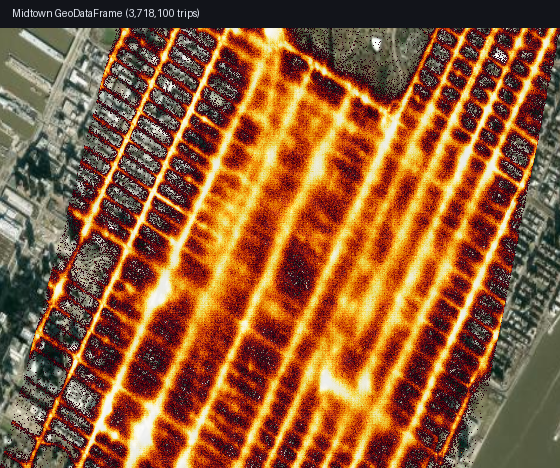

In [4]:
# Project Midtown Manhattan polygon on GPU and filter all 11.84M pickups in ~38 ms
midtown_lons = np.array([-74.0020, -73.9675, -73.9610, -73.9935], dtype=np.float32)
midtown_lats = np.array([ 40.7484,  40.7484,  40.7685,  40.7685], dtype=np.float32)
mx, my = vksp.lonlat_to_mercator(midtown_lons, midtown_lats)
midtown_poly = np.column_stack([mx.to_numpy(), my.to_numpy()]).astype(np.float32)

midtown_df = df[vksp.point_in_polygon(df["pickup_x"], df["pickup_y"], midtown_poly)]
gdf = vksp.GeoDataFrame(midtown_df, x="pickup_x", y="pickup_y")
print(f"Midtown Manhattan pickups: {len(gdf):,}")

# GeoDataFrame already knows its (x, y) columns — no need to pass them!
gdf.vkplot.points(tiles="esri", width=560, height=440, title=f"Midtown GeoDataFrame ({len(gdf):,} trips)")

## 4. OpenSky 10.23M Flight Trajectories — `.vkplot.paths()` & `.vkplot.plot3d()`

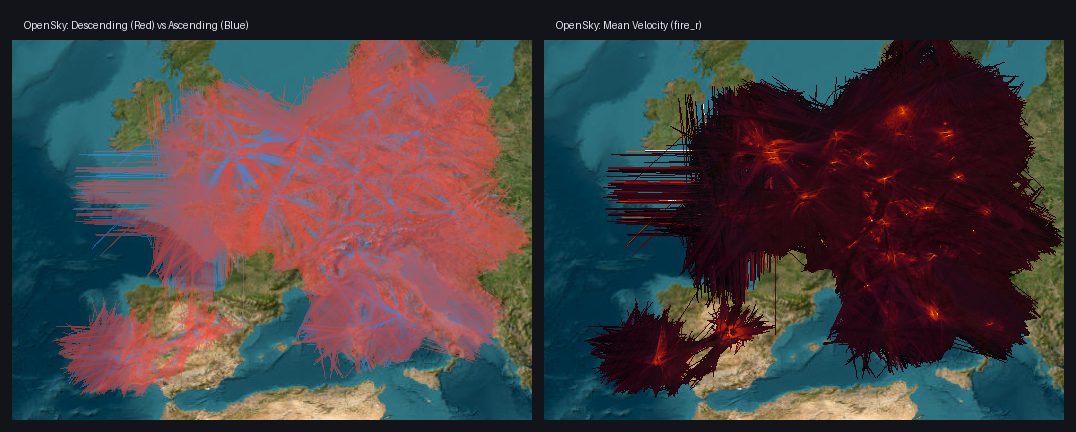

In [5]:
opensky_path = Path.home() / ".cache/vkdata/opensky/opensky.parq"
flights = vpd.read_parquet(opensky_path)
flights["longitude"] = flights["longitude"].astype(np.float32)
flights["latitude"]  = flights["latitude"].astype(np.float32)
flights["velocity"]  = flights["velocity"].astype(np.float32)
flights["ascending"] = flights["ascending"].astype(np.int32)

xr, yr = (-2.0e6, 2.5e6), (4.1e6, 7.8e6)
p_asc = flights.vkplot.paths(
    "longitude", "latitude", tiles="esri", by="ascending", color_key=["red", "blue"],
    width=520, height=380, xlim=xr, ylim=yr, title="OpenSky: Descending (Red) vs Ascending (Blue)",
)
p_vel = flights.vkplot.paths(
    "longitude", "latitude", tiles="esri", c="velocity", cmap="fire_r", vmin=0.0, vmax=260.0,
    width=520, height=380, xlim=xr, ylim=yr, title="OpenSky: Mean Velocity (fire_r)",
)
(p_asc + p_vel).cols(2)

In [6]:
# Interactive 3D Vulkan GPU orbit viewer in a single .vkplot.plot3d() call!
flights.vkplot.plot3d(
    "longitude", "latitude", "velocity",
    x_range=xr, y_range=yr, z_range=(0.0, 260.0),
    basemap="esri", z_scale=0.45, width=820, height=520,
    interact=True,
);